#### Set up

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

processed_data_directory = Path("../data/processed")

SERIES_COLOR = "#2a78d6"
plt.rcParams.update({
    "figure.figsize": (9, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.labelcolor": "#52514e",
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "#e8e7e2",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

#### Oscar data

In [2]:
oscars = pd.read_csv(processed_data_directory / "oscars_cleaned.csv")
oscars["Decade"] = oscars["Year"] // 10 * 10

print(f"{len(oscars):,} nominations from {oscars['Year'].min()} to {oscars['Year'].max()}")
oscars.head()

12,137 nominations from 1928 to 2025


,Ceremony,Year,Class,CanonicalCategory,Category,Film,FilmId,Name,Nominees,NomineeIds,Winner,Decade
0,1,1928,Acting,ACTOR IN A LEADING ROLE,ACTOR,The Noose|The Patent Leather Kid,tt0019217|tt0018253,Richard Barthelmess,Richard Barthelmess,nm0001932,False,1920
1,1,1928,Acting,ACTOR IN A LEADING ROLE,ACTOR,The Last Command|The Way of All Flesh,tt0019071|tt0019553,Emil Jannings,Emil Jannings,nm0417837,True,1920
2,1,1928,Acting,ACTRESS IN A LEADING ROLE,ACTRESS,A Ship Comes In,tt0018389,Louise Dresser,Louise Dresser,nm0237571,False,1920
3,1,1928,Acting,ACTRESS IN A LEADING ROLE,ACTRESS,7th Heaven|Street Angel|Sunrise,tt0018379|tt0019429|tt0018455,Janet Gaynor,Janet Gaynor,nm0310980,True,1920
4,1,1928,Acting,ACTRESS IN A LEADING ROLE,ACTRESS,Sadie Thompson,tt0019344,Gloria Swanson,Gloria Swanson,nm0841797,False,1920


In [3]:
oscars.groupby("Class").agg(
    nominations=("Winner", "size"),
    wins=("Winner", "sum"),
    categories=("CanonicalCategory", "nunique"),
).sort_values("nominations", ascending=False)

,nominations,wins,categories
Class,,,
Production,3292,697,16
Title,2788,587,13
Acting,1868,378,4
Music,1330,235,4
Writing,1037,211,4
SciTech,919,919,7
Directing,519,110,4
Special,384,378,14


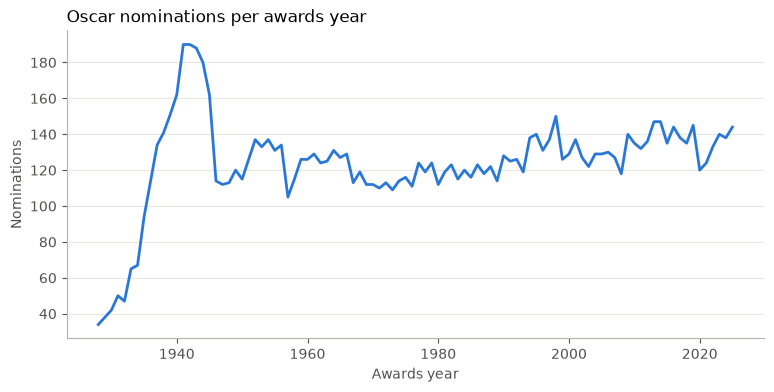

In [4]:
nominations_per_year = oscars.groupby("Year").size()

fig, ax = plt.subplots()
ax.plot(nominations_per_year.index, nominations_per_year.values, color=SERIES_COLOR, linewidth=2)
ax.set_title("Oscar nominations per awards year")
ax.set_xlabel("Awards year")
ax.set_ylabel("Nominations")
plt.show()

##### Visual categories

The categories closest to our question about visual quality. These categories changed over time,
so counts across decades aren't directly comparable.

In [5]:
VISUAL_CATEGORIES = "CINEMATOGRAPHY|ART DIRECTION|COSTUME|VISUAL EFFECTS|MAKEUP"

visual = oscars[oscars["CanonicalCategory"].str.contains(VISUAL_CATEGORIES)]

visual.groupby("CanonicalCategory").agg(
    nominations=("Winner", "size"),
    first_year=("Year", "min"),
    last_year=("Year", "max"),
)

,nominations,first_year,last_year
CanonicalCategory,,,
ART DIRECTION,377,1928,2025
ART DIRECTION (Black-and-White),138,1940,1966
ART DIRECTION (Color),112,1940,1966
CINEMATOGRAPHY,347,1928,2025
CINEMATOGRAPHY (Black-and-White),161,1939,1966
CINEMATOGRAPHY (Color),135,1939,1966
COSTUME DESIGN,305,1957,2025
COSTUME DESIGN (Black-and-White),77,1948,1966
COSTUME DESIGN (Color),77,1948,1966


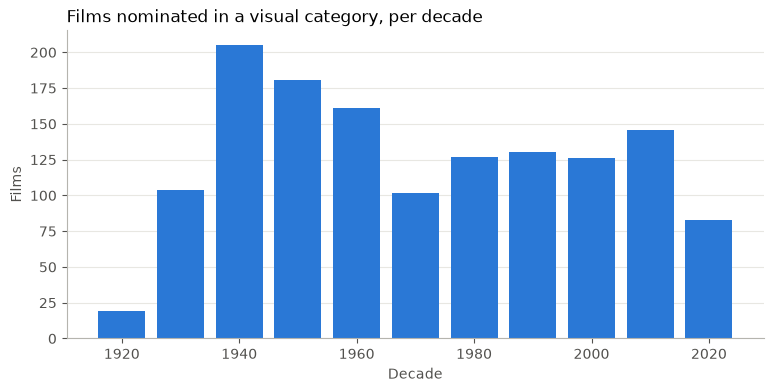

Decade
1920     19
1930    104
1940    205
1950    181
1960    161
1970    102
1980    127
1990    130
2000    126
2010    146
2020     83
Name: FilmId, dtype: int64

In [6]:
# A nomination can list several films (tt0019217|tt0018253), so split to one row per film
visual_films = visual.assign(FilmId=visual["FilmId"].str.split("|")).explode("FilmId")
visual_films_per_decade = visual_films.groupby("Decade")["FilmId"].nunique()

fig, ax = plt.subplots()
ax.bar(visual_films_per_decade.index, visual_films_per_decade.values, width=8, color=SERIES_COLOR)
ax.set_title("Films nominated in a visual category, per decade")
ax.set_xlabel("Decade")
ax.set_ylabel("Films")
plt.show()

visual_films_per_decade

#### IMDb data

In [7]:
imdb = pd.read_csv(processed_data_directory / "imdb_cleaned.csv")
imdb["decade"] = imdb["startYear"] // 10 * 10

print(f"{len(imdb):,} movies")
imdb[["startYear", "runtimeMinutes"]].describe()

708,304 movies


,startYear,runtimeMinutes
count,602267.000000,489275.000000
mean,1997.417048,89.885860
std,28.464738,113.370199
min,1894.000000,1.000000
25%,1982.000000,73.000000
50%,2010.000000,89.000000
75%,2019.000000,100.000000
max,2026.000000,51420.000000


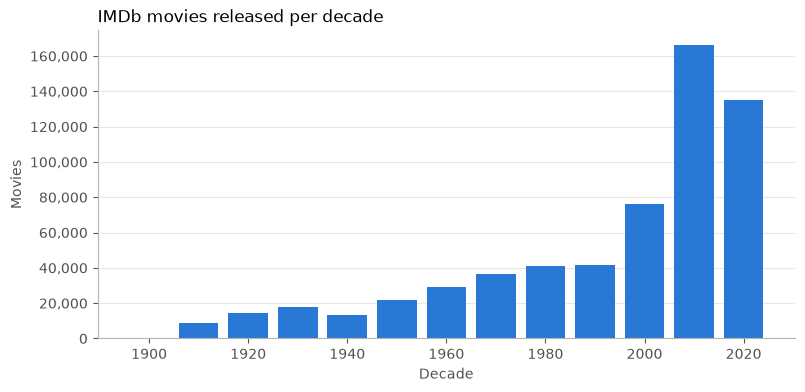

decade
1900.0       108
1910.0      8782
1920.0     14681
1930.0     17744
1940.0     13190
1950.0     21639
1960.0     29168
1970.0     36806
1980.0     40828
1990.0     41796
2000.0     76300
2010.0    166151
2020.0    135056
dtype: int64

In [8]:
movies_per_decade = imdb[imdb["decade"] >= 1900].groupby("decade").size()

fig, ax = plt.subplots()
ax.bar(movies_per_decade.index, movies_per_decade.values, width=8, color=SERIES_COLOR)
ax.set_title("IMDb movies released per decade")
ax.set_xlabel("Decade")
ax.set_ylabel("Movies")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
plt.show()

movies_per_decade

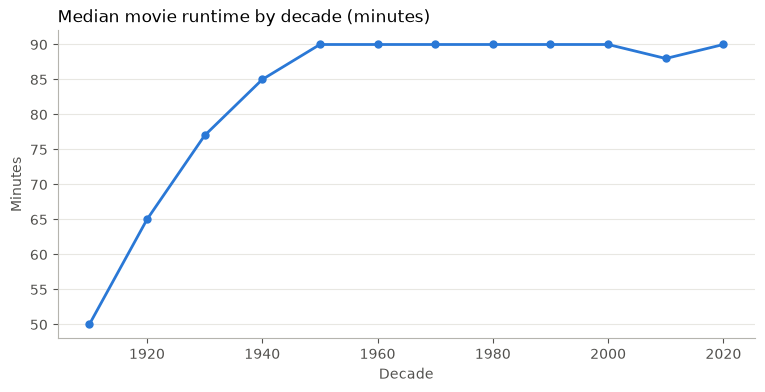

,median,count
decade,,
1910.0,50.0,4241
1920.0,65.0,7948
1930.0,77.0,12722
1940.0,85.0,11238
1950.0,90.0,17570
1960.0,90.0,23082
1970.0,90.0,30199
1980.0,90.0,33306
1990.0,90.0,33980


In [9]:
runtime_by_decade = imdb[imdb["decade"] >= 1910].groupby("decade")["runtimeMinutes"].agg(
    ["median", "count"]
)

fig, ax = plt.subplots()
ax.plot(runtime_by_decade.index, runtime_by_decade["median"], color=SERIES_COLOR,
        linewidth=2, marker="o", markersize=5)
ax.set_title("Median movie runtime by decade (minutes)")
ax.set_xlabel("Decade")
ax.set_ylabel("Minutes")
plt.show()

runtime_by_decade

##### Genres

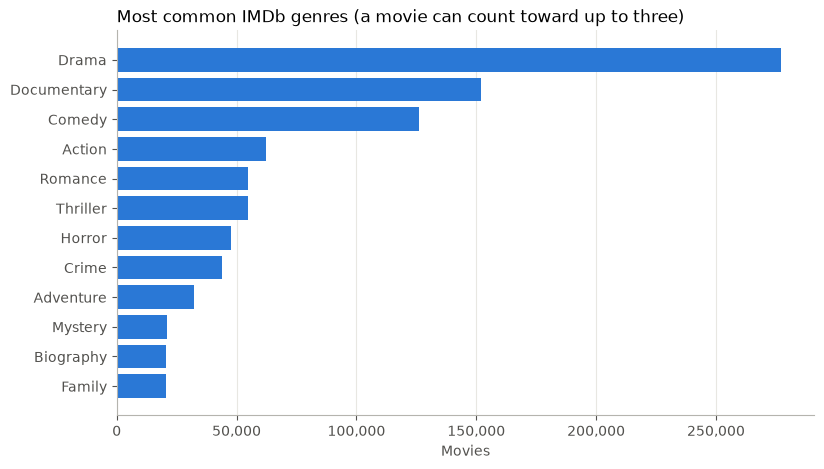

In [10]:
# A movie can have up to three genres (Comedy,Drama,Romance), so split to one row per genre
imdb_genres = imdb.assign(genre=imdb["genres"].str.split(",")).explode("genre").dropna(subset=["genre"])
top_genres = imdb_genres["genre"].value_counts().head(12)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_genres.index[::-1], top_genres.values[::-1], color=SERIES_COLOR)
ax.set_title("Most common IMDb genres (a movie can count toward up to three)")
ax.set_xlabel("Movies")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
plt.show()

In [11]:
ERA_BINS = [1890, 1959, 1999, 2026]
ERA_LABELS = ["Before 1960", "1960-1999", "2000 on"]

movies_per_era = pd.cut(imdb["startYear"], bins=ERA_BINS, labels=ERA_LABELS).value_counts()
imdb_genres["era"] = pd.cut(imdb_genres["startYear"], bins=ERA_BINS, labels=ERA_LABELS)

genre_share = (
    imdb_genres.groupby(["genre", "era"], observed=True).size()
    .unstack()
    .loc[top_genres.index]
    .div(movies_per_era)  # percent of that era's movies
    .mul(100)
    .round(1)
)
genre_share

era,Before 1960,1960-1999,2000 on
genre,,,
Drama,59.4,43.1,35.2
Documentary,6.1,11.6,31.8
Comedy,21.8,19.8,17.0
Action,4.8,12.5,7.4
Romance,12.8,9.7,6.8
Thriller,1.5,5.1,7.9
Horror,1.2,3.9,7.4
Crime,8.6,8.6,5.1
Adventure,5.6,5.6,3.8


In [12]:
MIN_VOTES = 1_000

rated = imdb[(imdb["numVotes"] >= MIN_VOTES) & (imdb["decade"] >= 1920)]

ratings_by_decade = rated.groupby("decade")["averageRating"].agg(["count", "mean", "median"]).round(2)
ratings_by_decade

,count,mean,median
decade,,,
1920.0,245,7.02,7.1
1930.0,822,6.79,6.8
1940.0,1146,6.80,6.8
1950.0,1631,6.65,6.8
1960.0,2042,6.61,6.7
1970.0,2632,6.46,6.6
1980.0,3384,6.27,6.4
1990.0,4347,6.33,6.5
2000.0,8487,6.20,6.4


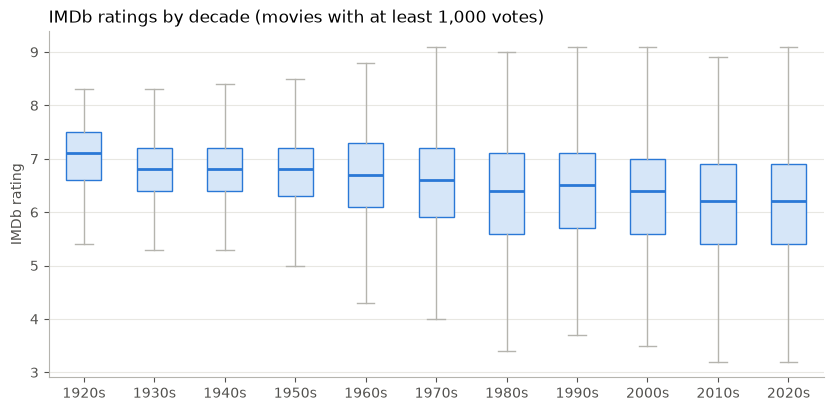

In [13]:
decades = ratings_by_decade.index

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot(
    [rated.loc[rated["decade"] == decade, "averageRating"] for decade in decades],
    tick_labels=[f"{decade:.0f}s" for decade in decades],
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": "#d6e6f8", "edgecolor": SERIES_COLOR},
    medianprops={"color": SERIES_COLOR, "linewidth": 2},
    whiskerprops={"color": "#b5b4ae"},
    capprops={"color": "#b5b4ae"},
)
ax.set_title(f"IMDb ratings by decade (movies with at least {MIN_VOTES:,} votes)")
ax.set_ylabel("IMDb rating")
plt.show()

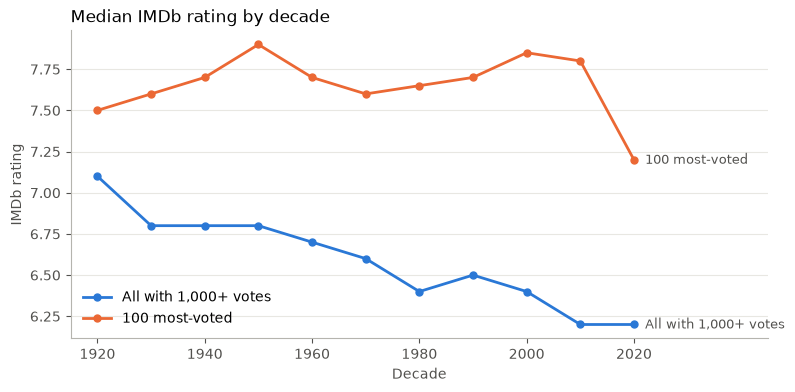

,"All with 1,000+ votes",100 most-voted
decade,,
1920.0,7.1,7.50
1930.0,6.8,7.60
1940.0,6.8,7.70
1950.0,6.8,7.90
1960.0,6.7,7.70
1970.0,6.6,7.60
1980.0,6.4,7.65
1990.0,6.5,7.70
2000.0,6.4,7.85


In [14]:
top_voted = rated.sort_values("numVotes", ascending=False).groupby("decade").head(100)

rating_comparison = pd.DataFrame({
    "All with 1,000+ votes": rated.groupby("decade")["averageRating"].median(),
    "100 most-voted": top_voted.groupby("decade")["averageRating"].median(),
})

fig, ax = plt.subplots()
for (label, values), color in zip(rating_comparison.items(), [SERIES_COLOR, "#eb6834"]):
    ax.plot(values.index, values.values, color=color, linewidth=2, marker="o", markersize=5, label=label)
    ax.annotate(label, (values.index[-1], values.iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color="#52514e")
ax.set_title("Median IMDb rating by decade")
ax.set_xlabel("Decade")
ax.set_ylabel("IMDb rating")
ax.set_xticks(range(1920, 2021, 20))
ax.set_xlim(right=rating_comparison.index.max() + 25)
ax.legend(loc="lower left", frameon=False)
plt.show()

rating_comparison

In [15]:
rated_genres = imdb_genres[imdb_genres["numVotes"] >= MIN_VOTES]

(
    rated_genres.groupby(["genre", "era"], observed=True)["averageRating"].median()
    .unstack()
    .loc[top_genres.index]
)

era,Before 1960,1960-1999,2000 on
genre,,,
Drama,6.90,6.80,6.5
Documentary,7.35,7.55,7.3
Comedy,6.80,6.50,6.1
Action,6.60,6.30,6.0
Romance,6.80,6.60,6.3
Thriller,6.85,6.20,5.8
Horror,6.10,5.60,5.1
Crime,6.80,6.50,6.3
Adventure,6.60,6.40,6.1
